In [26]:
import pymongo as pm
import pandas as pd

client = pm.MongoClient(
 'bigdatadb.polito.it',
 ssl=True,
 authSource='carsharing',
 username='ictts',
 password='Ict4SM22!',
 tlsAllowInvalidCertificates=True
)


In [2]:
db= client['carsharing']

In [3]:
pb_coll = db['PermanentBookings']
ap_coll = db['ActiveParkings']
ab_coll = db['ActiveParkings']
pp_coll = db['PermanentParkings']

In [4]:
pb_coll.count_documents({})

28180508

In [5]:
pp_coll.count_documents({})

28312676

In [6]:
pb_cities = pb_coll.distinct('city')
list(pb_cities)

['Amsterdam',
 'Austin',
 'Berlin',
 'Calgary',
 'Columbus',
 'Denver',
 'Firenze',
 'Frankfurt',
 'Hamburg',
 'Madrid',
 'Milano',
 'Montreal',
 'Munchen',
 'New York City',
 'Portland',
 'Rheinland',
 'Roma',
 'San Diego',
 'Seattle',
 'Stuttgart',
 'Torino',
 'Toronto',
 'Twin Cities',
 'Vancouver',
 'Washington DC',
 'Wien']

In [7]:
init_ap = ap_coll.find({},{'init_time':1,'_id':0}).sort('init_time',1).limit(1)

In [8]:
list(init_ap)

[{'init_time': 1516773360}]

In [9]:
final_ap = ap_coll.find({},{'final_time':1,'_id':0}).sort('final_time',-1).limit(1)

In [10]:
list(final_ap)

[{'final_time': -1}]

In [11]:
plate_list=pb_coll.distinct('plate',{'city' : 'Columbus'})

In [12]:
print(len(plate_list))

215


In [13]:
print(ab_coll.find_one())
print(ab_coll.count_documents({}))

{'_id': ObjectId('5a681ffa2ad85324efad4387'), 'plate': 'BDD7581', 'vendor': 'car2go', 'final_time': -1, 'loc': {'type': 'Point', 'coordinates': [-122.36057, 47.5188]}, 'init_time': 1516773360, 'vin': 'WDCTG4GB6HJ336162', 'smartPhoneRequired': True, 'interior': 'GOOD', 'exterior': 'GOOD', 'address': '9411-9415 21st Ave SW, Seattle, WA 98106, USA', 'init_date': datetime.datetime(2018, 1, 23, 21, 56), 'final_date': -1, 'city': 'Seattle', 'fuel': 100, 'engineType': 'CE'}
4790


#Step 2 - Car sharing usage Characterization

In [14]:
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import numpy as np

In [15]:
print(db['PermanentBookings'].find_one()) 

start = int(datetime(2017, 11, 1, tzinfo=timezone.utc).timestamp())
end   = int(datetime(2018, 2, 1, tzinfo=timezone.utc).timestamp())

cities = ["Torino","Columbus","Frankfurt"]

{'_id': ObjectId('5900e8bc2ad8531539ed0847'), 'init_fuel': 45, 'city': 'Vancouver', 'walking': {'duration': -1, 'distance': -1}, 'vendor': 'car2go', 'driving': {'duration': -1, 'distance': -1}, 'final_time': 1481650748, 'plate': '644XNS', 'engineType': 'CE', 'init_time': 1481650703, 'vin': 'WMEEJ3BA8EK762841', 'smartPhoneRequired': False, 'interior': 'GOOD', 'final_fuel': 45, 'exterior': 'GOOD', 'init_date': datetime.datetime(2016, 12, 13, 9, 38, 23), 'final_date': datetime.datetime(2016, 12, 13, 9, 39, 8), 'init_address': '1694 Duranleau,surface lot next t/Bridges.fits3', 'final_address': '1694 Duranleau,surface lot next t/Bridges.fits3', 'origin_destination': {'type': 'LineString', 'coordinates': [[-123.13606, 49.27269], [-123.13606, 49.27269]]}, 'public_transport': {'duration': -1, 'distance': -1, 'arrival_date': -1, 'arrival_time': -1}}


In [16]:

def load(coll, city):
    # pipe = [
    #     {"$match": {"city": city, "init_date": {"$gte": start, "$lt": end}}},
    #     {"$project": {"_id":0, "city":1, "init_date":1, "final_date":1,
    #                   "init_time":1, "final_time":1,
    #                   "duration": {"$subtract": ["$final_time","$init_time"]},
    #                   "origin_destination":1, "loc":1,"init_address":1,"final_address":1}}
    # ]
    pipe = [
        {"$match": {"city": city, "init_time": {"$gte": start, "$lt": end}}},
        {"$project": {"_id": 0, "init_time": 1,
                      "duration": {"$subtract": ["$final_time", "$init_time"]}}}
    ]
        
    df = pd.DataFrame(db[coll].aggregate(pipe, allowDiskUse=True))
    df["duration_min"] = df["duration"]/60
    return df

bookings = {c: load("PermanentBookings", c) for c in cities}
parkings = {c: load("PermanentParkings", c) for c in cities}

In [17]:
def best_zone(x, q=0.9, log=True):
    """
    Zone la plus dense : le plus petit intervalle [a, b] qui contient une fraction q
    des échantillons (sur la ECDF : F(b) - F(a) = q).
    log=True : la largeur est mesurée en log(durée), adapté aux durées très étalées
               -> on enlève à la fois les durées très courtes et la longue traîne.
               Les durées <= 0 (invalides) sont retirées avant le calcul.
    """
    x = np.sort(np.asarray(x, dtype=float))
    if log:
        x = x[x > 0]
    t = np.log(x) if log else x
    n = len(x)
    k = int(np.ceil(q * n))                 # nb de points à garder
    widths = t[k - 1:] - t[:n - k + 1]      # largeur de chaque fenêtre de k points consécutifs
    i = np.argmin(widths)
    return x[i], x[i + k - 1]


def keep_best_zone(df, q=0.9, col="duration_min", log=True):
    """Garde uniquement les lignes dont la durée est dans la zone la plus dense."""
    a, b = best_zone(df[col].values, q, log)
    return df[df[col].between(a, b)].copy(), (a, b)


Q = 0.90   # fraction de la ECDF à conserver

raw = {"bookings": bookings, "parkings": parkings}
filtered = {kind: {} for kind in raw}
zones = {}
for kind, data in raw.items():
    for c in cities:
        filtered[kind][c], zones[(kind, c)] = keep_best_zone(data[c], Q)
        a, b = zones[(kind, c)]
        n0, n1 = len(data[c]), len(filtered[kind][c])
        print(f"{kind:9s} {c:10s} zone = [{a:7.1f}, {b:8.1f}] min -> {n1}/{n0} gardés ({n1/n0:.1%})")

bookings_f = filtered["bookings"]
parkings_f = filtered["parkings"]

bookings  Torino     zone = [    0.8,     38.0] min -> 238053/264503 gardés (90.0%)
bookings  Columbus   zone = [    0.8,     44.0] min -> 47679/52976 gardés (90.0%)
bookings  Frankfurt  zone = [    0.8,     60.1] min -> 131902/146557 gardés (90.0%)
parkings  Torino     zone = [    0.8,    410.4] min -> 238088/264542 gardés (90.0%)
parkings  Columbus   zone = [    1.5,   1719.7] min -> 47631/52923 gardés (90.0%)
parkings  Frankfurt  zone = [    0.8,    432.1] min -> 132169/146854 gardés (90.0%)


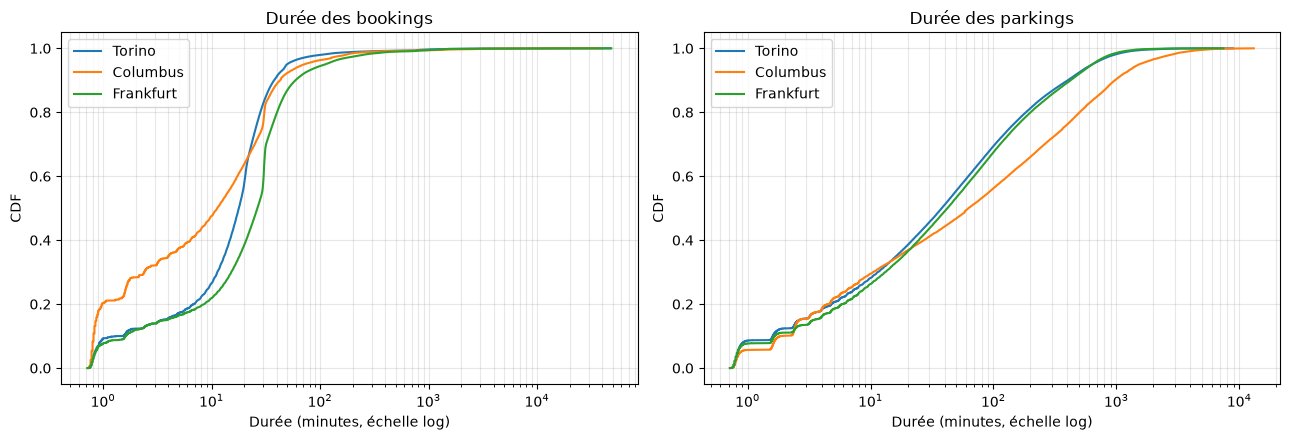

In [18]:
def plot_cdf(data_dict, title, ax):
    for city, df in data_dict.items():
        x = np.sort(df["duration_min"].values)
        x = x[x > 0]                                  # nécessaire pour l'axe log
        y = np.arange(1, len(x)+1) / len(x)
        ax.plot(x, y, label=city)
    ax.set_xscale("log")
    ax.set_xlabel("Durée (minutes, échelle log)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings, "Durée des bookings", axes[0])
plot_cdf(parkings, "Durée des parkings", axes[1])
plt.tight_layout(); plt.show()

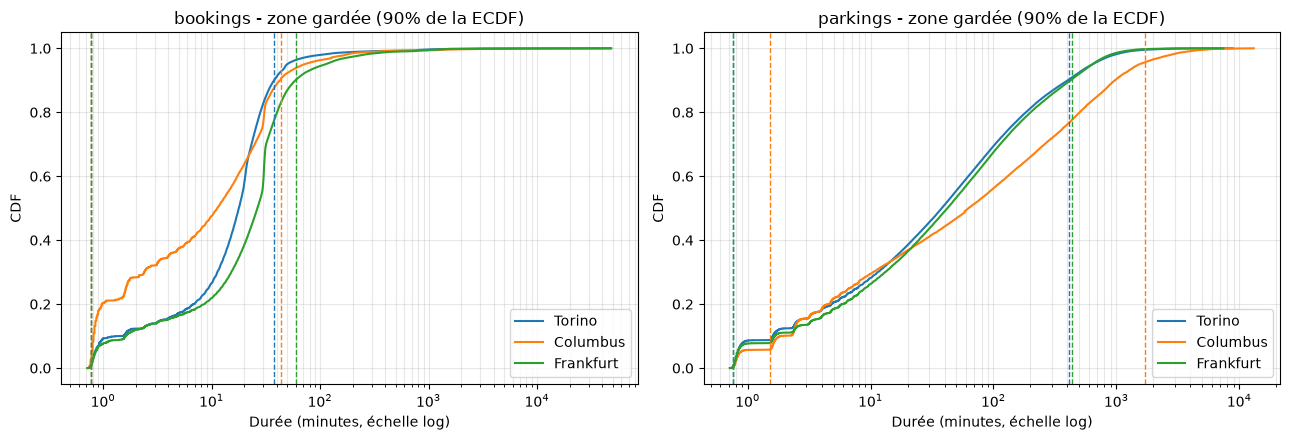

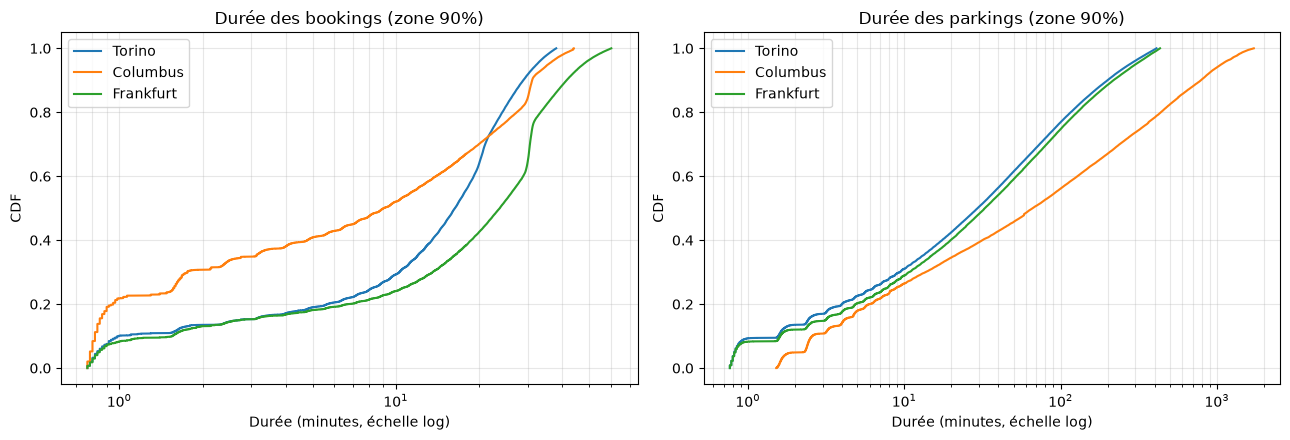

In [19]:
# ECDF complète + bornes de la zone gardée (pointillés, même couleur que la ville)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, kind in zip(axes, raw):
    plot_cdf(raw[kind], f"{kind} - zone gardée ({Q:.0%} de la ECDF)", ax)
    for line, c in zip(list(ax.get_lines()), cities):
        for v in zones[(kind, c)]:
            ax.axvline(v, color=line.get_color(), ls="--", lw=1)
plt.tight_layout(); plt.show()

# ECDF recalculée sur les données filtrées
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings_f, f"Durée des bookings (zone {Q:.0%})", axes[0])
plot_cdf(parkings_f, f"Durée des parkings (zone {Q:.0%})", axes[1])
plt.tight_layout(); plt.show()

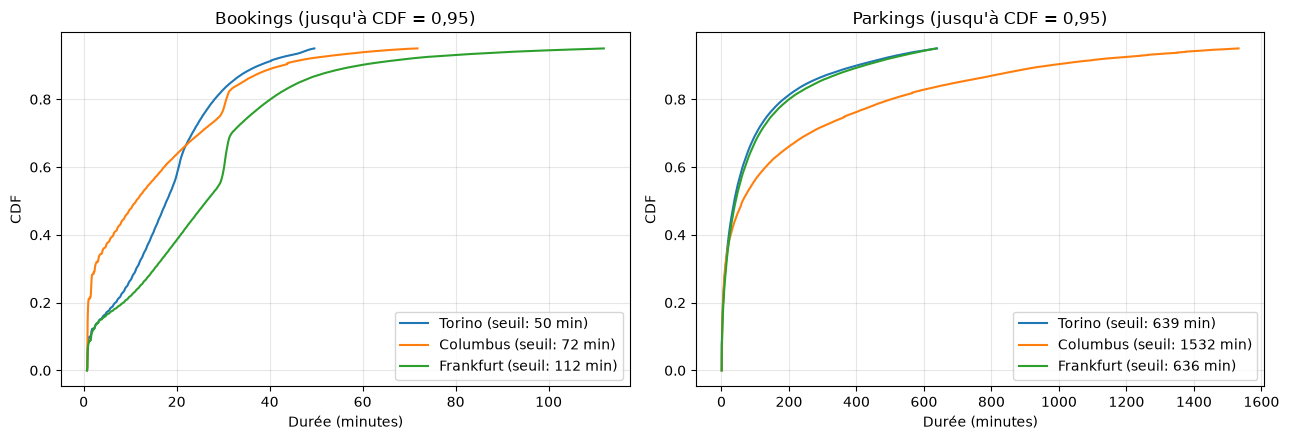

In [20]:
def remove_outliers(df, q=0.95, col="duration_min"):
    """Garde seulement les durées <= quantile q (par défaut le 95e percentile)."""
    threshold = df[col].quantile(q)
    return df[df[col] <= threshold].copy(), threshold

def plot_cdf_wo_outlier(data_dict, title, ax, q=0.95, renormalize=False, max_points=5000):
    """
    q            : on s'arrête quand la CDF atteint q (None = pas de coupure)
    renormalize  : False -> la courbe s'arrête à q (la CDF originale est conservée)
                   True  -> on retire les outliers et on recalcule la CDF (elle repart de 0 à 1)
    """
    for city, df in data_dict.items():
        x = np.sort(df["duration_min"].values)
        y = np.arange(1, len(x) + 1) / len(x)

        if q is not None:
            if renormalize:
                x = x[x <= np.quantile(x, q)]
                y = np.arange(1, len(x) + 1) / len(x)
            else:
                mask = y <= q
                x, y = x[mask], y[mask]

        idx = np.unique(np.linspace(0, len(x) - 1, max_points).astype(int))
        ax.plot(x[idx], y[idx], label=f"{city} (seuil: {x[-1]:.0f} min)")

    ax.set_xlabel("Durée (minutes)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()


    
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf_wo_outlier(bookings, "Bookings (jusqu'à CDF = 0,95)", axes[0], q=0.95)
plot_cdf_wo_outlier(parkings, "Parkings (jusqu'à CDF = 0,95)", axes[1], q=0.95)
plt.tight_layout(); plt.show()


#1
With the results we can see that the majority of the booking are around 20/30min.
But this depends on the city that we are looking. For Frankfurt bookings are longer than Torino or Columbus.

a) The longest booking duration is in Frankfurt this was not to be expected when we look at the size of each cities Columbus is 580m² Torino 130m² and Frankfurt 248m². 
This booking is for 33days which is too much.
The CDF suggest the present of outliers as there are only a few bookings that are very very loong

b) We can interpret the difference in the CDF, as a difference in usage of booking in the user.
For instance there is more booking for 3-15min in columbus than in frankfurt

c)


In [21]:
# print(bookings)

In [22]:
def load_wtime(coll, city):
    pipe = [
        {"$match": {"city": city, "init_time": {"$gte": start, "$lt": end}}},
        {"$project": {"_id": 0, 
                      "init_time": 1,
                      "duration": {"$subtract": ["$final_time", "$init_time"]},
                      "day":      {"$dateToString": {"date": "$init_date", "format": "%Y-%m-%d"}},
                        "week":     {"$isoWeek": "$init_date"},
                        "iso_year": {"$isoWeekYear": "$init_date"},
                        "dow":      {"$isoDayOfWeek": "$init_date"},
                        "hour":     {"$hour": "$init_date"},}}           
    ]
        
    df = pd.DataFrame(db[coll].aggregate(pipe, allowDiskUse=True))
    df["duration_min"] = df["duration"]/60
    return df



bookings_wtime = {c: load_wtime("PermanentBookings", c) for c in cities}
parkings_wtime = {c: load_wtime("PermanentParkings", c) for c in cities}


In [23]:
# Même requête que load() -> on réutilise les bornes de zone déjà calculées
bookings_wtime_f = {c: df[df["duration_min"].between(*zones[("bookings", c)])].copy()
                    for c, df in bookings_wtime.items()}
parkings_wtime_f = {c: df[df["duration_min"].between(*zones[("parkings", c)])].copy()
                    for c, df in parkings_wtime.items()}

In [24]:
# print(bookings_wtime)

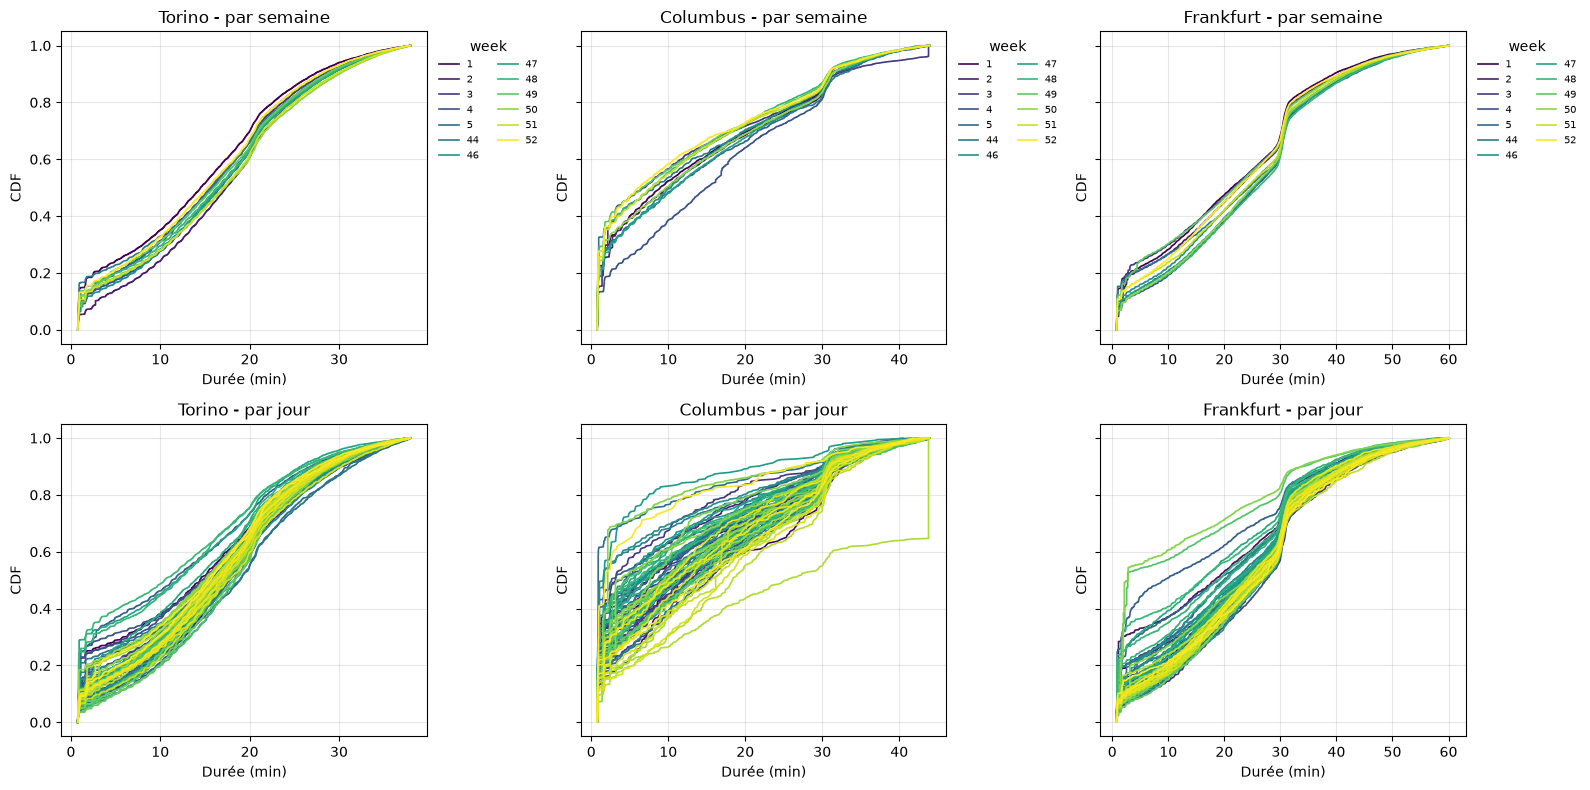

In [25]:

def ecdf(x):
    x = np.sort(np.asarray(x))
    return x, np.arange(1, len(x) + 1) / len(x)


def plot_cdf_by(df, col, ax, title="", cmap="viridis", legend=True,
                log=False, xmax=None):
    groups = sorted(df[col].unique())
    colors = plt.get_cmap(cmap)(np.linspace(0, 1, len(groups)))
    for c, g in zip(colors, groups):
        x, y = ecdf(df.loc[df[col] == g, "duration_min"])
        ax.plot(x, y, color=c, lw=1.2, label=str(g))

    if log:
        ax.set_xscale("log")
    elif xmax is not None:
        ax.set_xlim(0, xmax)          # échelle linéaire, zoomée

    ax.set_xlabel("Durée (min)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(alpha=.3)
    if legend:
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  fontsize=7, ncol=2, frameon=False,
                  title=col)
        

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)

for j, city in enumerate(cities):
    df = pd.DataFrame(bookings_wtime_f[city])    # données filtrées sur la zone la plus dense

    plot_cdf_by(df, "week", axes[0, j], f"{city} - par semaine")
    plot_cdf_by(df, "day",  axes[1, j], f"{city} - par jour", legend=False)  # trop de jours pour une légende

plt.tight_layout()
plt.show()

# Q3 
For the outlier we can say that we could stop if we have 95% of the CDF.
We can also remove le beginning or try to find the best zone to look in.